# Assignment 2: Logistic Regression on the Iris Dataset

**Berkay Aydin - [Student ID removed]**

## 1. Introduction

In this assignment, I will build a logistic regression model from scratch using the Iris dataset from the UCI Machine Learning Repository. The goal is to classify two different types of Iris flowers based on their measurements.

I chose Iris-versicolor and Iris-virginica for this experiment. Instead of using all four available features, I will focus on petal length and petal width. I want to see how well a model can separate these two flowers using only two measurements.

I will first explore the dataset and visualize the selected features. Then, I will split the data into training and testing sets, implement logistic regression using the equations discussed in class, and train the model by updating its weights. Finally, I will evaluate the model using classification accuracy and examine how its performance changes during training.

## 2. Dataset Preparation

The Iris dataset contains 150 samples from three different flower species: Iris-setosa, Iris-versicolor, and Iris-virginica. Each sample has four measurements: sepal length, sepal width, petal length, and petal width.

For this assignment, I will only use Iris-versicolor and Iris-virginica. This gives me 100 samples in total, with 50 samples from each species.

I selected petal length and petal width as the two input features. Since logistic regression is being used for binary classification, I will convert the flower names into numerical labels:

- Iris-versicolor = 0
- Iris-virginica = 1

This will allow the model to learn the relationship between the two measurements and the flower type.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

iris_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

iris_data = pd.read_csv(iris_url, header=None, names=columns)

print(iris_data)
print(iris_data["species"].value_counts())

display(iris_data.describe())



     sepal_length  sepal_width  petal_length  petal_width         species
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, d

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Selecting Features and Classes

I chose Iris-versicolor and Iris-virginica because their petal measurements overlap in some areas. I wanted to see if logistic regression could separate them.

I used petal length and petal width as my two features. I also changed the flower names into 0 and 1 so I could use them in my model.

In [2]:

# I chose versicolor and virginica to work with two species that have overlapping petal measurements.
flower_pair = ["Iris-versicolor", "Iris-virginica"]
petal_measurements = ["petal_length", "petal_width"]

# I filter out setosa since I only need two classes for this experiment.
petal_study = iris_data[
    iris_data["species"].isin(flower_pair)
].copy()

# I keep the two petal measurements and the species names before encoding them.
petal_study = petal_study[
    petal_measurements + ["species"]
].copy()

# I use 0 for versicolor and 1 for virginica to represent my two classes.
flower_labels = {
    "Iris-versicolor": 0,
    "Iris-virginica": 1
}

petal_study["target"] = petal_study["species"].map(flower_labels)

# I now keep only the two inputs and the numerical target for my model.
petal_study = petal_study[
    petal_measurements + ["target"]
].copy()

# I check the size and class balance before moving on to visualization.
print("Selected observations:", len(petal_study))
print("\nSamples per class:")
print(petal_study["target"].value_counts().sort_index())

display(petal_study.head())


Selected observations: 100

Samples per class:
target
0    50
1    50
Name: count, dtype: int64


,petal_length,petal_width,target
50,4.7,1.4,0
51,4.5,1.5,0
52,4.9,1.5,0
53,4.0,1.3,0
54,4.6,1.5,0


## 4. Visualizing the Selected Flowers

Before training my model, I want to see how the two flower species are distributed based on their petal measurements.

I will plot petal length on the x-axis and petal width on the y-axis. I will use different colors for Iris-versicolor and Iris-virginica so I can compare their measurements and see where the two species overlap.

This will also help me understand whether a linear decision boundary could separate the flowers reasonably well.

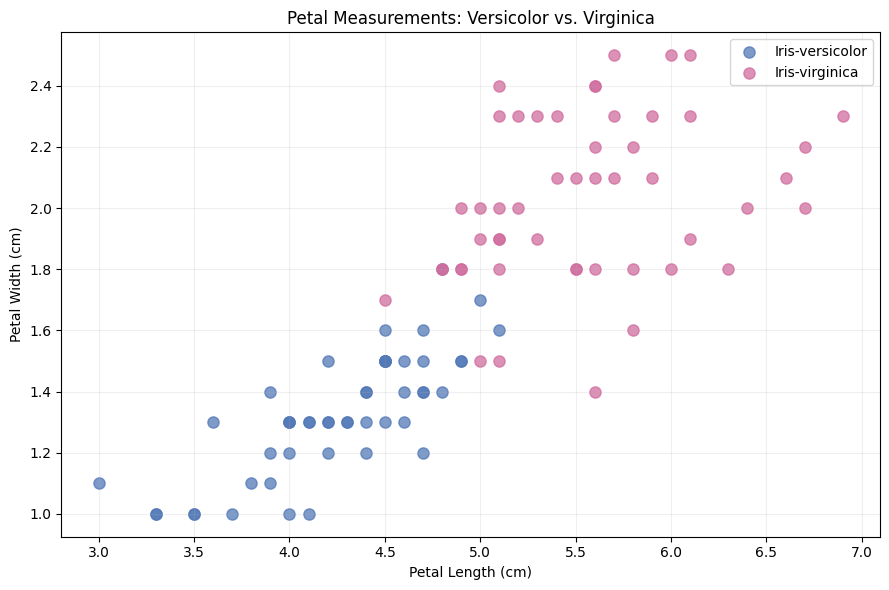

In [3]:

# I separate the two species so I can compare their petal measurements.
versicolor_petals = petal_study[petal_study["target"] == 0]
virginica_petals = petal_study[petal_study["target"] == 1]

plt.figure(figsize=(9, 6))

# I plot versicolor in blue and virginica in pink to make the overlap easier to see.
plt.scatter(
    versicolor_petals["petal_length"],
    versicolor_petals["petal_width"],
    color="#5278B7",
    label="Iris-versicolor",
    alpha=0.75,
    s=65
)

plt.scatter(
    virginica_petals["petal_length"],
    virginica_petals["petal_width"],
    color="#D16C9E",
    label="Iris-virginica",
    alpha=0.75,
    s=65
)

plt.title("Petal Measurements: Versicolor vs. Virginica")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 5. Splitting the Data into Training and Testing Sets

I divided my 100 selected flower samples into 80% training data and 20% testing data.

Since I have 50 samples from each species, I decided to split them separately instead of randomly dividing the entire dataset at once. This way, I can keep both classes equally represented in the training and testing sets.

I randomly selected 40 samples from each species for training and kept the remaining 10 from each species for testing. I also used a fixed random seed so I can reproduce the same split when running the notebook again.

I will use the 80 training samples to update the model's weights and keep the 20 testing samples separate until the final evaluation.

In [4]:

# I use a fixed seed so I can reproduce my random split.
random_generator = np.random.default_rng(42)

# I separate the flower samples before splitting them.
versicolor_samples = petal_study[petal_study["target"] == 0]
virginica_samples = petal_study[petal_study["target"] == 1]

# I randomly shuffle the rows of each species independently.
versicolor_order = random_generator.permutation(len(versicolor_samples))
virginica_order = random_generator.permutation(len(virginica_samples))

versicolor_shuffled = versicolor_samples.iloc[versicolor_order]
virginica_shuffled = virginica_samples.iloc[virginica_order]

# I take 40 samples from each species for training.
training_flowers = pd.concat([
    versicolor_shuffled.iloc[:40],
    virginica_shuffled.iloc[:40]
])

# I reserve the remaining 10 samples from each species for testing.
testing_flowers = pd.concat([
    versicolor_shuffled.iloc[40:],
    virginica_shuffled.iloc[40:]
])

# I shuffle the combined training and testing sets separately.
training_flowers = training_flowers.sample(
    frac=1, random_state=42
).reset_index(drop=True)

testing_flowers = testing_flowers.sample(
    frac=1, random_state=42
).reset_index(drop=True)

# I check the number of samples and class balance in both sets.
print("TRAINING DATA")
print("Total samples:", len(training_flowers))
print(training_flowers["target"].value_counts().sort_index())

print("\nTESTING DATA")
print("Total samples:", len(testing_flowers))
print(testing_flowers["target"].value_counts().sort_index())

display(training_flowers.head())
display(testing_flowers.head())


TRAINING DATA
Total samples: 80
target
0    40
1    40
Name: count, dtype: int64

TESTING DATA
Total samples: 20
target
0    10
1    10
Name: count, dtype: int64


,petal_length,petal_width,target
0,4.0,1.3,0
1,4.5,1.3,0
2,4.5,1.5,0
3,4.2,1.3,0
4,3.5,1.0,0


,petal_length,petal_width,target
0,4.7,1.4,0
1,5.5,2.1,1
2,5.4,2.1,1
3,4.0,1.0,0
4,4.7,1.4,0


I used 80% of the data for training and 20% for testing. I also kept the number of samples from each flower type balanced in both sets. This way, I could train the model using both classes equally and test it on data it had not seen before.

## 6. Building My Logistic Regression Model

I will implement logistic regression without using a machine learning library. I want to understand how the model makes predictions and how its weights change during training, rather than relying on a built-in function.

My model uses petal length and petal width as inputs. I will start by calculating a weighted sum of these two measurements along with a bias term.

$$
z = w_1x_1 + w_2x_2 + b
$$

I will then pass this value through the sigmoid function to get a prediction between 0 and 1.

$$
\hat{y} = \frac{1}{1+e^{-z}}
$$

Since I assigned 1 to Iris-virginica, the output represents the model's estimated probability of a flower belonging to that class. I will use 0.5 as the classification threshold.

In [5]:

# I use sigmoid to convert the model's weighted score into a value between 0 and 1.
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# I check the sigmoid output for a few values before using it in my model.
sample_scores = [-4, -2, 0, 2, 4]

for score in sample_scores:
    print(f"z = {score:>2} | sigmoid = {sigmoid(score):.4f}")


z = -4 | sigmoid = 0.0180
z = -2 | sigmoid = 0.1192
z =  0 | sigmoid = 0.5000
z =  2 | sigmoid = 0.8808
z =  4 | sigmoid = 0.9820


In [6]:
# I separate the input features and target labels.
X_train = training_flowers[["petal_length", "petal_width"]].to_numpy()
y_train = training_flowers["target"].to_numpy()

X_test = testing_flowers[["petal_length", "petal_width"]].to_numpy()
y_test = testing_flowers["target"].to_numpy()

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (80, 2)
Training labels: (80,)
Testing features: (20, 2)
Testing labels: (20,)


In [7]:

# I start with zero weights so I can observe how training changes them.
petal_weights = np.array([0.0, 0.0])
petal_bias = 0.0

# I calculate the weighted score for one flower.
first_flower = X_train[0]

initial_score = (
    petal_weights[0] * first_flower[0]
    + petal_weights[1] * first_flower[1]
    + petal_bias
)

initial_probability = sigmoid(initial_score)

print("Petal measurements:", first_flower)
print("Actual class:", y_train[0])
print("Initial score:", initial_score)
print("Initial probability:", initial_probability)


Petal measurements: [4.  1.3]
Actual class: 0
Initial score: 0.0
Initial probability: 0.5


In [8]:
# I use binary cross-entropy to measure prediction error.
def compute_loss(y_actual, y_predicted):
    epsilon = 1e-15
    y_predicted = np.clip(y_predicted, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_actual * np.log(y_predicted)
        + (1 - y_actual) * np.log(1 - y_predicted)
    )

    return loss


# I calculate the initial loss before training.
initial_predictions = sigmoid(
    X_train @ petal_weights + petal_bias
)

initial_loss = compute_loss(y_train, initial_predictions)

print("Initial training loss:", initial_loss)

Initial training loss: 0.6931471805599453


In [9]:
# I train my logistic regression model using gradient descent.
learning_rate = 0.1
epochs = 1000

petal_weights = np.array([0.0, 0.0])
petal_bias = 0.0

loss_history = []
accuracy_history = []

for epoch in range(epochs):
    scores = X_train @ petal_weights + petal_bias
    predictions = sigmoid(scores)

    errors = predictions - y_train
    weight_gradients = (X_train.T @ errors) / len(y_train)
    bias_gradient = np.mean(errors)

    petal_weights -= learning_rate * weight_gradients
    petal_bias -= learning_rate * bias_gradient

    updated_predictions = sigmoid(X_train @ petal_weights + petal_bias)

    current_loss = compute_loss(y_train, updated_predictions)
    loss_history.append(current_loss)

    predicted_classes = (updated_predictions >= 0.5).astype(int)
    current_accuracy = np.mean(predicted_classes == y_train) * 100
    accuracy_history.append(current_accuracy)

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}: Loss = {current_loss:.4f}, Accuracy = {current_accuracy:.2f}%")

print("\nFinal weights:", petal_weights)
print("Final bias:", petal_bias)
print("Final training accuracy:", accuracy_history[-1], "%")

Epoch 100: Loss = 0.6116, Accuracy = 66.25%
Epoch 200: Loss = 0.5558, Accuracy = 83.75%
Epoch 300: Loss = 0.5120, Accuracy = 83.75%
Epoch 400: Loss = 0.4768, Accuracy = 91.25%
Epoch 500: Loss = 0.4480, Accuracy = 91.25%
Epoch 600: Loss = 0.4241, Accuracy = 91.25%
Epoch 700: Loss = 0.4039, Accuracy = 91.25%
Epoch 800: Loss = 0.3865, Accuracy = 91.25%
Epoch 900: Loss = 0.3714, Accuracy = 91.25%
Epoch 1000: Loss = 0.3582, Accuracy = 91.25%

Final weights: [-0.10397434  3.11992364]
Final bias: -4.495857673255913
Final training accuracy: 91.25 %


I used a learning rate of 0.1 and trained the model for 1000 epochs. These settings allowed me to observe how the model improved during training. The loss decreased from approximately 0.6931 to 0.3582, and the final training accuracy reached 91.25%. Based on these results, the selected settings worked reasonably well for this dataset.

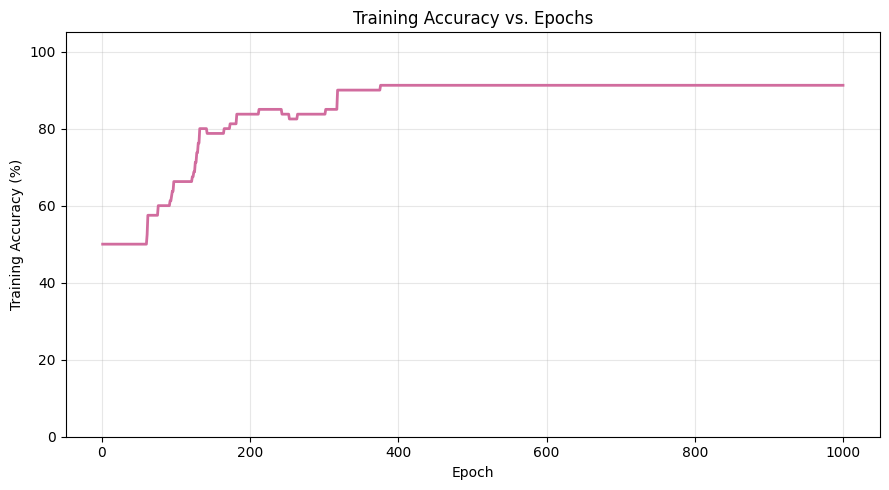

In [10]:
# Plot training accuracy over 1000 epochs
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    accuracy_history,
    color="#D16C9E",
    linewidth=2
)

plt.title("Training Accuracy vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The training accuracy increased during the first few hundred epochs and reached 91.25%. After that, it stayed almost the same until the end of training.

### 6.1 Gradient Calculation

I used gradient descent to train my model. First, I calculate the weighted sum using the two features, weights, and bias.

$$
z = w_1x_1 + w_2x_2 + b
$$

Then I use the sigmoid function to get a probability between 0 and 1.

$$
\hat{y} = \frac{1}{1+e^{-z}}
$$

I use binary cross-entropy to calculate the loss.

$$
J = -\frac{1}{m}\sum_{i=1}^{m}[y_i\log(\hat{y}_i)+(1-y_i)\log(1-\hat{y}_i)]
$$

Next, I calculate the gradients for the weights and bias.

$$
\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)x_{ij}
$$

$$
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)
$$

I use these gradients to update the weights and bias.

$$
w_j = w_j - \alpha\frac{\partial J}{\partial w_j}
$$

$$
b = b - \alpha\frac{\partial J}{\partial b}
$$

I used a learning rate of 0.1 and trained the model for 1000 epochs. I also checked the loss and accuracy during training to see how the model improved.

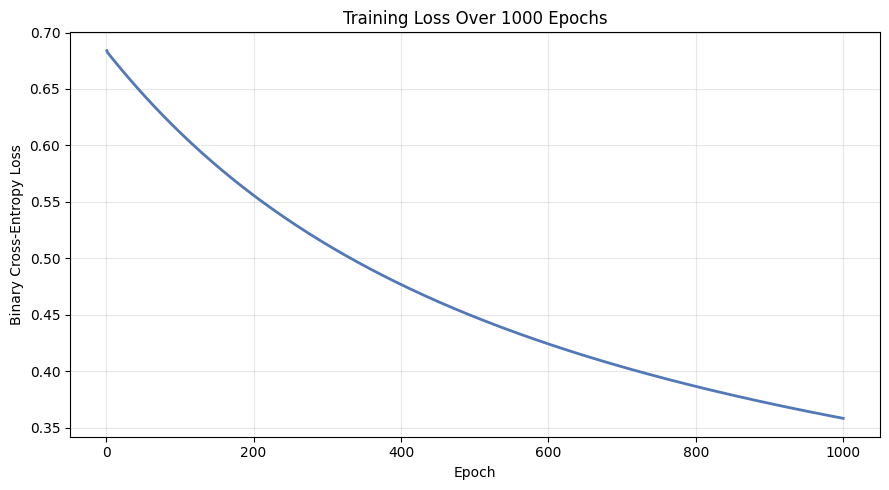

In [11]:
# I plot the training loss to see how my model improved over time.
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history,
    color="#5278B7",
    linewidth=2
)

plt.title("Training Loss Over 1000 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# I use the trained model to predict the test samples.
test_scores = X_test @ petal_weights + petal_bias
test_probabilities = sigmoid(test_scores)

# I convert probabilities into class labels.
test_predictions = (test_probabilities >= 0.5).astype(int)

# I compare predictions with actual labels.
test_accuracy = np.mean(test_predictions == y_test)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Correct predictions:", np.sum(test_predictions == y_test))
print("Total test samples:", len(y_test))

Test Accuracy: 95.0 %
Correct predictions: 19
Total test samples: 20


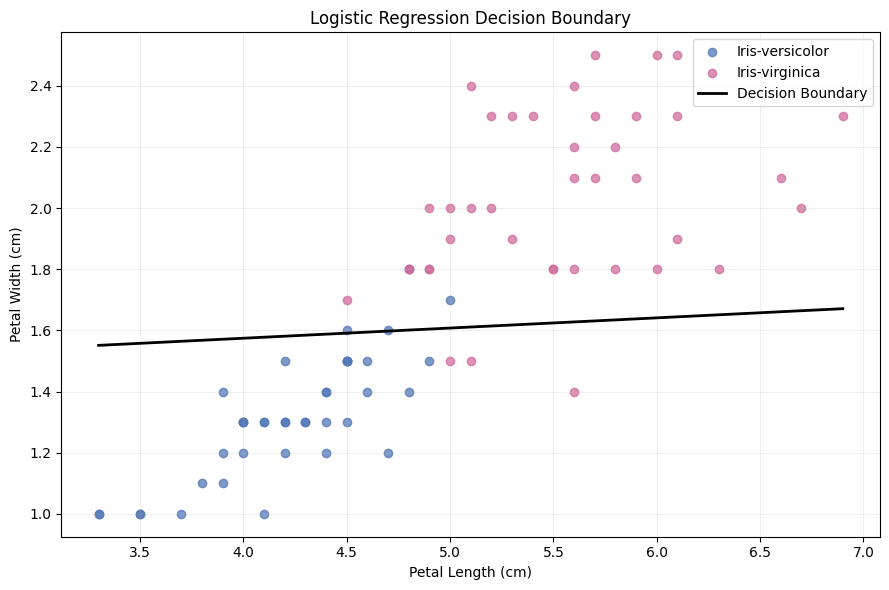

In [13]:
# I visualize the decision boundary learned by my logistic regression model.
plt.figure(figsize=(9, 6))

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    color="#5278B7",
    label="Iris-versicolor",
    alpha=0.75
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    color="#D16C9E",
    label="Iris-virginica",
    alpha=0.75
)

# I calculate the boundary where the predicted probability is 0.5.
x_values = np.linspace(
    X_train[:, 0].min(),
    X_train[:, 0].max(),
    100
)

y_values = -(
    petal_weights[0] * x_values + petal_bias
) / petal_weights[1]

plt.plot(
    x_values,
    y_values,
    color="black",
    linewidth=2,
    label="Decision Boundary"
)

plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

The decision boundary shows where the model separates the two flower types. Points on different sides of the line are predicted as different classes. Some flowers are close to the line, so the model may have trouble classifying them correctly.

## 7. Results and Discussion

After training the model for 1000 epochs, the loss decreased from 0.6931 to 0.3582. The training accuracy reached 91.25%, and the test accuracy was 95%.

The final weights were [-0.1040, 3.1199], and the bias was -4.4959.

From the graphs, I could see that the loss decreased as training continued. The training accuracy also improved, but it did not increase much during the last few hundred epochs.

The decision boundary shows how the model separates the two flower species using petal length and petal width. Some points are close to the boundary, which makes them harder to classify.

## 8. Conclusion

In this assignment, I built a logistic regression model from scratch to classify Iris-versicolor and Iris-virginica using petal length and petal width.

My model achieved 95% test accuracy. I learned how sigmoid, binary cross-entropy, and gradient descent work together during training.

The graphs also helped me understand how the model improved over time. Overall, this assignment helped me understand logistic regression better by implementing it myself instead of using a machine learning library.

## 9. Logistic Regression on the Iris Dataset Report

### 9.1 Dataset and Feature Selection

For this assignment, I used the Iris dataset from the UCI Machine Learning Repository as it was mentioned in the instructions. The original dataset contains 150 samples from three flower species: Iris-setosa, Iris-versicolor, and Iris-virginica.

I selected Iris-versicolor and Iris-virginica because their petal measurements overlap in some areas. I wanted to see whether logistic regression could separate these two species using only two features.

I chose petal length and petal width as my input features. I assigned label 0 to Iris-versicolor and label 1 to Iris-virginica.

After filtering the dataset, I had 100 samples, with 50 samples from each species. I also created a scatter plot to see how the flowers were distributed.

### 9.2 Training and Testing Data

I divided the 100 samples into 80 training samples and 20 testing samples.

I shuffled each class separately and randomly selected 40 samples from each species for training. I used the remaining 10 samples from each species for testing.

I used a random seed of 42 so that I could reproduce the same split.

| Dataset | Versicolor | Virginica | Total |
|---|---:|---:|---:|
| Training | 40 | 40 | 80 |
| Testing | 10 | 10 | 20 |

This kept both classes balanced in the training and testing sets. I used only the training data to update the model's weights and bias.

### 9.3 Logistic Regression Model

I implemented logistic regression from scratch using NumPy without using a machine learning library.

First, I calculated the weighted sum of the two input features:

$$
z = w_1x_1 + w_2x_2 + b
$$

Here, $x_1$ is petal length, $x_2$ is petal width, $w_1$ and $w_2$ are the weights, and $b$ is the bias.

Then, I used the sigmoid function to convert the weighted sum into a probability:

$$
\hat{y} = \frac{1}{1+e^{-z}}
$$

Since Iris-virginica is labeled as 1, the output represents the predicted probability of a flower being Iris-virginica.

I used 0.5 as the classification threshold. Predictions greater than or equal to 0.5 were classified as Iris-virginica, and predictions below 0.5 were classified as Iris-versicolor.

### 9.4 Loss Function and Gradient Calculation

I used binary cross-entropy to calculate the prediction error:

$$
J = -\frac{1}{m}\sum_{i=1}^{m}
\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

Here, $m$ is the number of training samples, $y_i$ is the actual class label, and $\hat{y}_i$ is the predicted probability.

To train the model, I calculated the gradients of the loss with respect to the weights and bias.

The gradient for each weight is:

$$
\frac{\partial J}{\partial w_j}
=
\frac{1}{m}\sum_{i=1}^{m}
(\hat{y}_i-y_i)x_{ij}
$$

The gradient for the bias is:

$$
\frac{\partial J}{\partial b}
=
\frac{1}{m}\sum_{i=1}^{m}
(\hat{y}_i-y_i)
$$

I used gradient descent to update the weights and bias:

$$
w_j \leftarrow w_j-\alpha\frac{\partial J}{\partial w_j}
$$

$$
b \leftarrow b-\alpha\frac{\partial J}{\partial b}
$$

I used a learning rate of 0.1 and trained the model for 1000 epochs. During training, I recorded the loss and training accuracy after each epoch.

### 9.5 Training Results

I initialized both weights and the bias to zero. Before training, the binary cross-entropy loss was approximately 0.6931.

After 1000 epochs, the loss decreased to 0.3582, and the training accuracy reached 91.25%.

The final model parameters were:

| Parameter | Value |
|---|---:|
| Weight for petal length ($w_1$) | -0.1040 |
| Weight for petal width ($w_2$) | 3.1199 |
| Bias ($b$) | -4.4959 |
| Learning rate | 0.1 |
| Epochs | 1000 |

The training accuracy increased during the first few hundred epochs and then stayed around 91.25%.

The loss continued to decrease throughout training, even when the classification accuracy was no longer changing much.

### 9.6 Testing Results

After training, I evaluated the model using the 20 testing samples.

The model correctly classified 19 out of 20 samples.

$$
\text{Test Accuracy} = \frac{19}{20}\times100 = 95\%
$$

The final results were:

| Metric | Result |
|---|---:|
| Initial training loss | 0.6931 |
| Final training loss | 0.3582 |
| Training accuracy | 91.25% |
| Test accuracy | 95% |
| Correct test predictions | 19 out of 20 |

The test accuracy was slightly higher than the training accuracy. Since I only used 20 samples for testing, the result could change with a different random split.

### 9.7 Decision Boundary and Discussion

I also plotted the decision boundary learned by the logistic regression model.

The boundary represents the points where the predicted probability is 0.5. Flowers on one side of the boundary are predicted as Iris-versicolor, while flowers on the other side are predicted as Iris-virginica.

The graph showed that the model could separate most of the samples using petal length and petal width. However, some flowers were close to the boundary because the two species have overlapping measurements.

Overall, the model performed well using only two features. The accuracy and loss graphs also helped me understand how the model improved during training.

### 9.8 Conclusion

In this assignment, I implemented logistic regression from scratch to classify Iris-versicolor and Iris-virginica using petal length and petal width.

I used binary cross-entropy to measure prediction error and gradient descent to update the weights and bias. After 1000 epochs, the model achieved 91.25% training accuracy and 95% test accuracy.

By implementing the model myself, I learned how the sigmoid function, loss calculation, gradients, and parameter updates work together.

The graphs also helped me understand how the model improved during training and how it separated the two flower species.


## Google Colab Notebook

The complete code, training results, and graphs are available in my Google Colab notebook.

**Notebook Link:** Notebook included in this repository